# 5 — Modèle de scoring · Segment : Comptes joints

**Objectif** : dérouler le chapitre 5 du cours sur les variables discrétisées du notebook `4`. On combine les variables
en un score unique par régression logistique, on sélectionne le sous-ensemble le plus parcimonieux, et on le confronte
à un modèle concurrent.

| § | Thème | Traitement appliqué ici |
|---|-------|-------------------------|
| 5.1 | Régression logistique | dummies, **modalité 1 (la moins risquée) en référence**, tests globaux / par variable / par modalité, IC95 % des odds ratios |
| 5.2 | Modèle concurrent | gradient boosting sur les variables brutes préparées (jamais retenu comme modèle final) |
| 5.3 | Métriques d'ordonnancement | AUC, Gini et son IC95 % (Hanley & McNeil), KS, courbes ROC / CAP, lift, test de DeLong |
| 5.4 | Parcimonie | LASSO logistique en passe exploratoire |
| 5.5 | Stepwise par ordre de liaison | **méthode de sélection retenue** : ajout par IV décroissant, validation de tous les tests à chaque étape |

> **Échantillons** (cours 1.5) : le modèle est estimé sur l'**apprentissage** ; le **test** (20 % des dossiers, tiré
> en `2`) mesure la performance hors échantillon. L'échantillon **Out-of-Time** sera une base fournie séparément.
>
> Ce notebook est un **rapport lisible** : les calculs sont délégués à `utils/modele.py`.

> **Variante v2** (comparaison avec la version de référence `5 - Modele_joint`) : avant le stepwise, les classes 2 et 3 de
> `MINSOLDE_PAR` (β quasi identiques) sont fusionnées ; pendant le stepwise, une variable déjà retenue rendue non
> conforme par une candidate voit sa classe fautive fusionnée avec sa voisine, au lieu d'écarter la candidate.
> Exports suffixés `_v2`. **Les commentaires rédigés plus bas décrivent la version de référence.**

## 0. Imports et configuration

In [5]:
import sys, json
from pathlib import Path

# Racine du projet : ce notebook est rangé dans Segmentation_joint/
ROOT = Path.cwd().parent if Path.cwd().name == "Segmentation_joint" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

from utils.binning import iv_ranking
from utils.modele import (
    bilan_echantillons, ajuster_logit, tests_modele, appliquer_fusions, stepwise_liaison, lasso_exploratoire,
    performance, test_delong, table_lift, gradient_boosting, predire_gb,
    gini_cv_logit, gini_cv_gb, importance_permutation_gb, ajouts_un_a_un,
    plot_journal, plot_coefficients, plot_roc_cap,
)
from utils.exploration import exporter_excel
from sklearn.metrics import roc_auc_score

%matplotlib inline
plt.rcParams["figure.dpi"] = 120
pl.Config.set_tbl_rows(60)
pl.Config.set_fmt_str_lengths(60)

polars.config.Config

### Paramètres

| Paramètre | Valeur | Justification |
|-----------|--------|---------------|
| `ALPHA` | 5 % | seuil des tests de Wald (par modalité) et du LR test (par variable) — cours 5.1 |
| `GAIN_MIN` | 0,5 point de Gini | gain marginal minimal pour retenir une variable (critère d'arrêt, cours 5.5) |
| `SEUIL_VIF` | 5 | multicolinéarité préoccupante au-delà (cours 3.4), contrôlée entre variables du modèle |

In [6]:
BASE_CL    = ROOT.parent / "data/segments/joint/base_joint_classes.parquet"   # sortie de 4 (variables en classes)
BASE_PREP  = ROOT.parent / "data/segments/joint/base_joint_prep.parquet"      # sortie de 2 (variables brutes préparées)
DECOUPAGES = ROOT / "outputs/binning/decoupages_joint.json"
CANDIDATES = ROOT / "outputs/exploration/variables_candidates_joint.json"
SORTIE_MOD = ROOT / "outputs/modele/modele_joint_v2.json"
SORTIE_XLS = ROOT / "outputs/modele/modele_joint_v2.xlsx"

TARGET = "ddefaut_ndb"

ALPHA     = 0.05
GAIN_MIN  = 0.005
SEUIL_VIF = 5

# Variante v2
FUSIONS_INITIALES = {"MINSOLDE_PAR": {1: 1, 2: 2, 3: 2, 4: 3}}   # classes 2 et 3 : β quasi identiques
FUSION_RETENUES = True

## 1. Chargement

In [7]:
df = pl.read_parquet(BASE_CL)
VARS = list(json.loads(DECOUPAGES.read_text(encoding="utf-8")))   # variables retenues au ch. 4

df_app  = df.filter(pl.col("echantillon") == "apprentissage")
df_test = df.filter(pl.col("echantillon") == "test")

print(f"{len(VARS)} variables discrétisées en entrée")
bilan_echantillons(df, TARGET)

39 variables discrétisées en entrée


echantillon,n,n_defaut,taux_defaut,part
str,u32,f64,f64,f64
"""apprentissage""",47156,228.0,0.004835,0.799973
"""test""",11791,56.0,0.004749,0.200027


## 5.1 Régression logistique : principe et modalité de référence

Chaque variable discrétisée devient un jeu d'indicatrices, une par classe, **sauf la classe 1** (la moins risquée,
numérotation du ch. 4) qui sert de référence. L'odds ratio e^β d'une classe se lit alors uniformément, pour toutes les
variables, comme le **surrisque relatif de cette classe par rapport à la classe la moins risquée**. Un β positif
signale une classe plus risquée que la référence : la monotonie β₂ < β₃ < … < β_N est attendue.

Un modèle n'est candidat que s'il satisfait **simultanément** :

| Niveau | Test |
|--------|------|
| global | LR test contre le modèle nul |
| variable | LR test de la variable (modèle avec / sans), VIF ≤ 5 |
| modalité | Wald p < 5 %, IC95 % de l'odds ratio n'incluant pas 1, signe positif, monotonie des β |

### Préclassement des candidates par IV (cours 5.5, étape 1)

L'IV est recalculé sur le **découpage final** et sur l'**apprentissage** : il porte exactement sur la discrétisation
injectée dans le modèle. C'est un ordre d'examen, pas une sélection.

In [8]:
iv_final = iv_ranking(df_app, VARS, TARGET, max_modalites=10**6)
ORDRE = iv_final["variable"].to_list()
iv_final

variable,iv,pouvoir,n_classes,min_n_classe
str,f64,str,i64,i64
"""MINSOLDE_PAR""",1.728506,"""suspect""",4,4707
"""solde_crediteur""",1.526525,"""suspect""",4,2357
"""CRTAD_AG_NBJDE_BA""",1.488197,"""suspect""",4,4706
"""CRTAD_IND_0015""",1.312001,"""suspect""",4,2345
"""ENCOURS_PAR""",1.095889,"""suspect""",3,7073
"""RATIO_NBJDEB_NONAUTO_SUR_NBJDEB""",1.089998,"""suspect""",2,14144
"""ARR_GDT""",0.886608,"""suspect""",2,1545
"""NBJDE_RATIO_A_vs_A1""",0.771149,"""suspect""",4,3832
"""RATIO_SOLDE_MOYEN_SUR_EPARGNE""",0.597723,"""suspect""",3,1778


## 5.4 Passe exploratoire : LASSO

Le cours (5.4) présente la régularisation comme un outil de **dégrossissage**, pas comme la méthode de sélection finale
(elle ne garantit ni la monotonie, ni la significativité par modalité). Elle sert ici de point de comparaison avec la
sélection pas à pas : une variable que le LASSO annule entièrement apporte peu d'information propre.

In [9]:
lasso, C_lasso = lasso_exploratoire(df_app, ORDRE, TARGET)
print(f"C retenu par validation croisée : {C_lasso:.4g} | "
      f"{lasso['retenue_lasso'].sum()} variables sur {lasso.height} gardent au moins un coefficient non nul")
lasso

c:\Users\anisz\OneDrive\Desktop\Scorign\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
c:\Users\anisz\OneDrive\Desktop\Scorign\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
c:\Users\anisz\OneDrive\Desktop\Scorign\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2129:

KeyboardInterrupt: 

## 5.5 Stepwise par ordre de liaison (méthode retenue)

Procédure du cours, appliquée à chaque candidate dans l'ordre d'IV décroissant :

1. **ajout** de la variable (toutes ses modalités à la fois) ;
2. **validation** de tous les tests de 5.1 sur le modèle complet. Si une modalité de la nouvelle variable n'est pas
   conforme (non significative, IC de l'OR contenant 1, rupture de monotonie ou signe négatif), elle est **fusionnée
   avec la classe adjacente moins risquée** — c'est le « retour au chapitre 4 » prévu par le cours — et le modèle est
   réestimé ; une variable réduite à une seule classe est écartée ;
3. une variable qui rend **non conforme une variable déjà retenue**, ou qui fait dépasser le VIF de 5, est écartée ;
4. la variable n'est retenue que si son **LR test** est significatif et si elle apporte au moins **0,5 point de Gini**
   d'apprentissage (gain marginal, critère d'arrêt).

Le Gini de **test** est affiché à chaque étape pour information : il ne sert pas à la sélection, pour rester une mesure
hors échantillon honnête.

In [10]:
res = stepwise_liaison(df_app, ORDRE, TARGET, df_test=df_test, alpha=ALPHA, gain_min=GAIN_MIN, seuil_vif=SEUIL_VIF,
                       fusions_initiales=FUSIONS_INITIALES, fusion_retenues=FUSION_RETENUES)

VARS_MODELE = res.variables
print(f"{len(VARS_MODELE)} variables retenues sur {len(ORDRE)} candidates")
with pl.Config(tbl_rows=-1, fmt_str_lengths=70, tbl_cols=-1):
    display(res.journal.select("etape", "variable", "statut", "motif", "n_classes_initial", "n_classes_final",
                               "gini_app", "gain_gini", "gini_test"))

9 variables retenues sur 39 candidates


etape,variable,statut,motif,n_classes_initial,n_classes_final,gini_app,gain_gini,gini_test
i64,str,str,str,i64,i64,f64,f64,f64
1,"""MINSOLDE_PAR""","""retenue""","""""",3,3,0.634462,0.634462,0.626961
2,"""solde_crediteur""","""retenue""","""""",4,4,0.717302,0.08284,0.673512
3,"""CRTAD_AG_NBJDE_BA""","""retenue""","""""",4,4,0.740198,0.022897,0.725843
4,"""CRTAD_IND_0015""","""écartée""","""une seule classe après fusions""",4,1,null,null,null
5,"""ENCOURS_PAR""","""retenue""","""""",3,2,0.777669,0.037471,0.738018
6,"""RATIO_NBJDEB_NONAUTO_SUR_NBJDEB""","""écartée""","""gain de Gini insuffisant (+0.26%)""",2,2,0.780291,0.002621,null
7,"""ARR_GDT""","""retenue""","""""",2,2,0.789467,0.011797,0.75406
8,"""NBJDE_RATIO_A_vs_A1""","""écartée""","""une seule classe après fusions""",4,1,null,null,null
9,"""RATIO_SOLDE_MOYEN_SUR_EPARGNE""","""écartée""","""une seule classe après fusions""",3,1,null,null,null


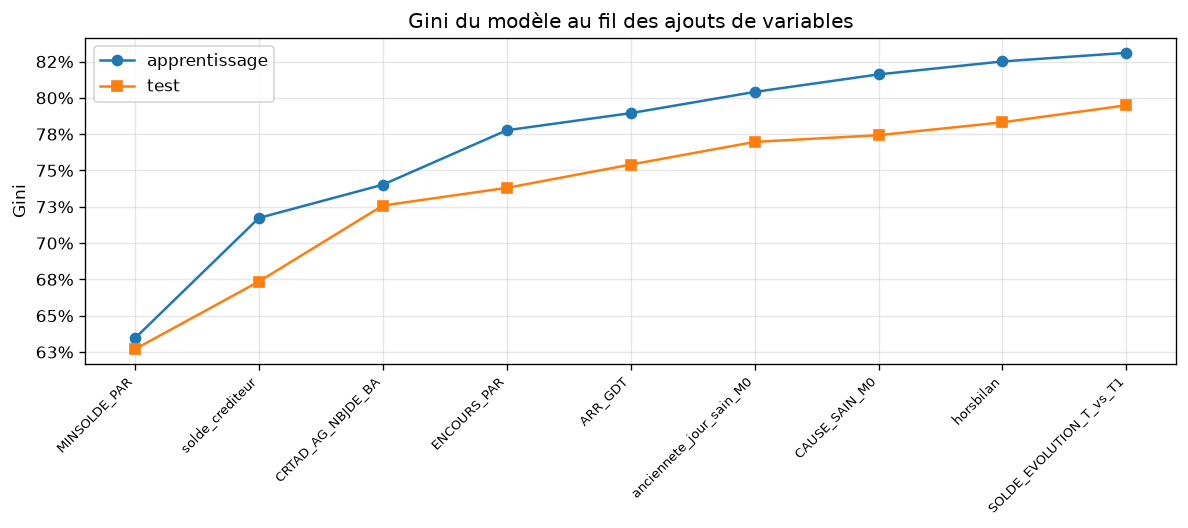

In [11]:
fig = plot_journal(res.journal)
plt.show()

In [12]:
# Motifs d'exclusion
res.journal.filter(pl.col("statut") == "écartée").with_columns(
    motif_court=pl.col("motif").str.replace(r" \(.*", "").str.replace(r"rend non conforme .*", "rend non conforme une variable retenue")
).group_by("motif_court").len().sort("len", descending=True)

motif_court,len
str,u32
"""une seule classe après fusions""",16
"""gain de Gini insuffisant""",7
"""rend non conforme une variable retenue""",7


## Modèle retenu : coefficients et tests de validité (cours 5.1)

Les fusions de classes décidées pendant la sélection sont appliquées aux deux échantillons ; le modèle est réestimé sur
l'apprentissage et l'ensemble des tests est recalculé, y compris le LR test de chaque variable (modèle sans elle).

In [13]:
FUSIONS = res.fusions
app_f, test_f = appliquer_fusions(df_app, FUSIONS), appliquer_fusions(df_test, FUSIONS)

modele = ajuster_logit(app_f, VARS_MODELE, TARGET)
test_global, test_variables, test_modalites = tests_modele(modele, app_f, TARGET, alpha=ALPHA, seuil_vif=SEUIL_VIF)

print(f"LR test global : LR = {test_global['lr']:.1f} ({test_global['ddl']} ddl), p = {test_global['pvalue']:.2e} | "
      f"pseudo-R² de McFadden = {test_global['pseudo_r2']:.3f} | β0 = {modele.beta0:.3f}")
print(f"Fusions appliquées : {FUSIONS or 'aucune'}")
test_variables

LR test global : LR = 767.2 (14 ddl), p = 1.14e-154 | pseudo-R² de McFadden = 0.266 | β0 = -8.811
Fusions appliquées : {'MINSOLDE_PAR': {1: 1, 2: 2, 3: 2, 4: 3}, 'ENCOURS_PAR': {1: 1, 2: 1, 3: 2}, 'anciennete_jour_sain_M0': {1: 1, 2: 1, 3: 2, 4: 3}, 'solde_crediteur': {1: 1, 2: 1, 3: 1, 4: 2}, 'SOLDE_EVOLUTION_T_vs_T1': {1: 1, 2: 2, 3: 2, 4: 3}}


variable,n_classes,lr,pvalue_lr,monotone,vif,modalites_significatives,ic_exclut_1,signes_ok,conforme
str,i64,f64,f64,bool,f64,bool,bool,bool,bool
"""MINSOLDE_PAR""",3,21.941448,0.000017,true,2.020363,true,true,true,true
"""solde_crediteur""",2,3.894468,0.048445,true,1.286892,true,true,true,true
"""CRTAD_AG_NBJDE_BA""",4,38.419061,2.3042e-8,true,1.942425,true,true,true,true
"""ENCOURS_PAR""",2,51.771804,6.2341e-13,true,1.120952,true,true,true,true
"""ARR_GDT""",2,15.628755,0.000077,true,1.157397,true,true,true,true
"""anciennete_jour_sain_M0""",3,20.829905,0.00003,true,1.069834,true,true,true,true
"""CAUSE_SAIN_M0""",2,45.190348,1.7878e-11,true,1.033629,true,true,true,true
"""horsbilan""",2,33.475721,7.2159e-9,true,1.145431,true,true,true,true
"""SOLDE_EVOLUTION_T_vs_T1""",3,13.734755,0.001041,true,1.106688,true,true,true,true


In [14]:
with pl.Config(tbl_rows=-1):
    display(test_modalites.select("variable", "classe", "beta", "se", "pvalue", "odds_ratio", "or_ic_bas", "or_ic_haut"))

variable,classe,beta,se,pvalue,odds_ratio,or_ic_bas,or_ic_haut
str,i64,f64,f64,f64,f64,f64,f64
"""MINSOLDE_PAR""",1,0.0,null,null,1.0,null,null
"""MINSOLDE_PAR""",2,0.804755,0.236935,0.000682,2.236149,1.405456,3.557821
"""MINSOLDE_PAR""",3,1.213454,0.271507,0.000008,3.365089,1.976449,5.72938
"""solde_crediteur""",1,0.0,null,null,1.0,null,null
"""solde_crediteur""",2,0.318658,0.161207,0.048076,1.375281,1.002695,1.886313
"""CRTAD_AG_NBJDE_BA""",1,0.0,null,null,1.0,null,null
"""CRTAD_AG_NBJDE_BA""",2,0.99221,0.286391,0.000531,2.69719,1.538618,4.72816
"""CRTAD_AG_NBJDE_BA""",3,1.347789,0.258257,1.8010e-7,3.848905,2.320088,6.385134
"""CRTAD_AG_NBJDE_BA""",4,1.649567,0.282663,5.3531e-9,5.204723,2.990818,9.057435


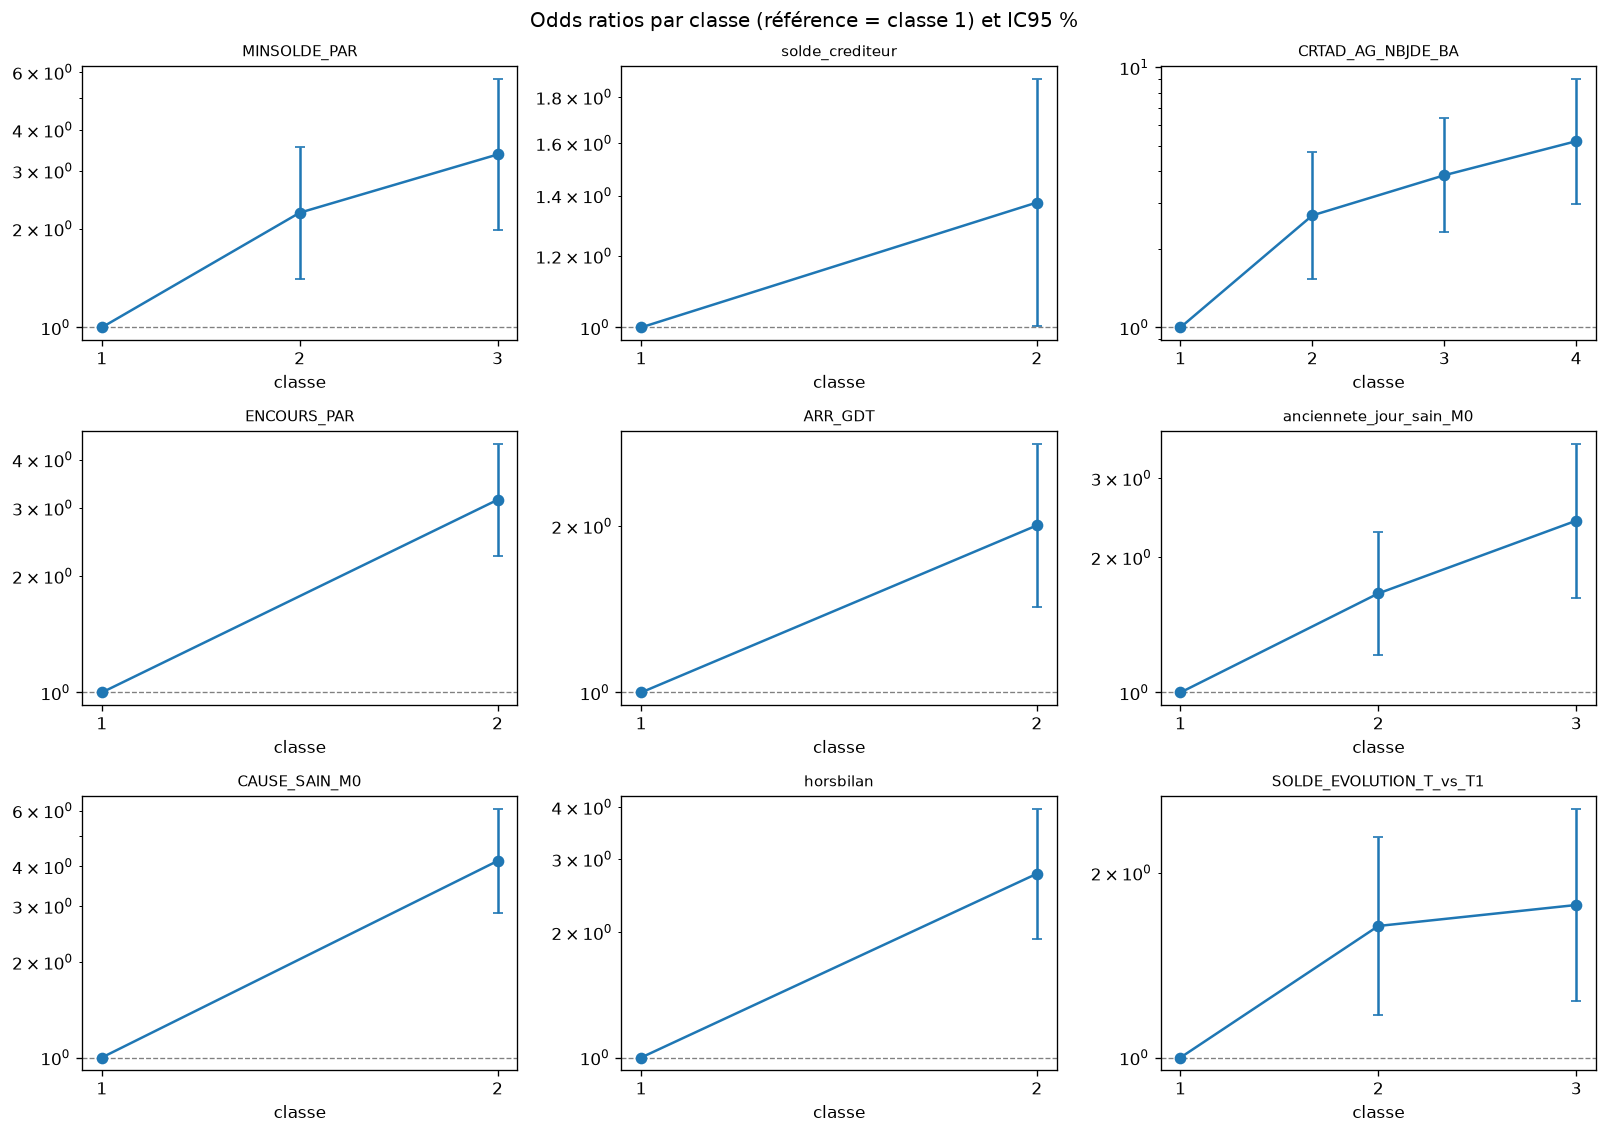

In [15]:
fig = plot_coefficients(test_modalites)
plt.show()

## 5.3 Métriques d'ordonnancement

Pas de métrique à seuil (cours 5.3.0) : le score sert à ordonner, la décision viendra après la mise en classe et le
calibrage. On mesure sur l'apprentissage et sur le test :

- **AUC** : probabilité qu'un défaut tiré au hasard ait un score plus risqué qu'un sain tiré au hasard ;
- **Gini** = 2·AUC − 1, avec son IC95 % (Hanley & McNeil) : avec peu de défauts, l'incertitude est large ;
- **KS** : écart maximal entre les répartitions des sains et des défauts.

Repères de place (cours 5.3.2) : Gini < 40 % faible, 40–60 % correct à bon, > 60 % fort.

In [16]:
s_app, s_test = modele.score_lineaire(app_f), modele.score_lineaire(test_f)
perf_lr = pl.DataFrame([performance(app_f[TARGET], s_app, "logistique — apprentissage"),
                        performance(test_f[TARGET], s_test, "logistique — test")])
perf_lr

modele,n,n_defaut,auc,gini,gini_ic_bas,gini_ic_haut,ks,auc_pr,ratio_pr
str,i64,i64,f64,f64,f64,f64,f64,f64,f64
"""logistique — apprentissage""",47156,228,0.915498,0.830996,0.781056,0.880935,0.697303,0.104672,21.648793
"""logistique — test""",11791,56,0.897442,0.794884,0.685534,0.904234,0.671677,0.084335,17.757039


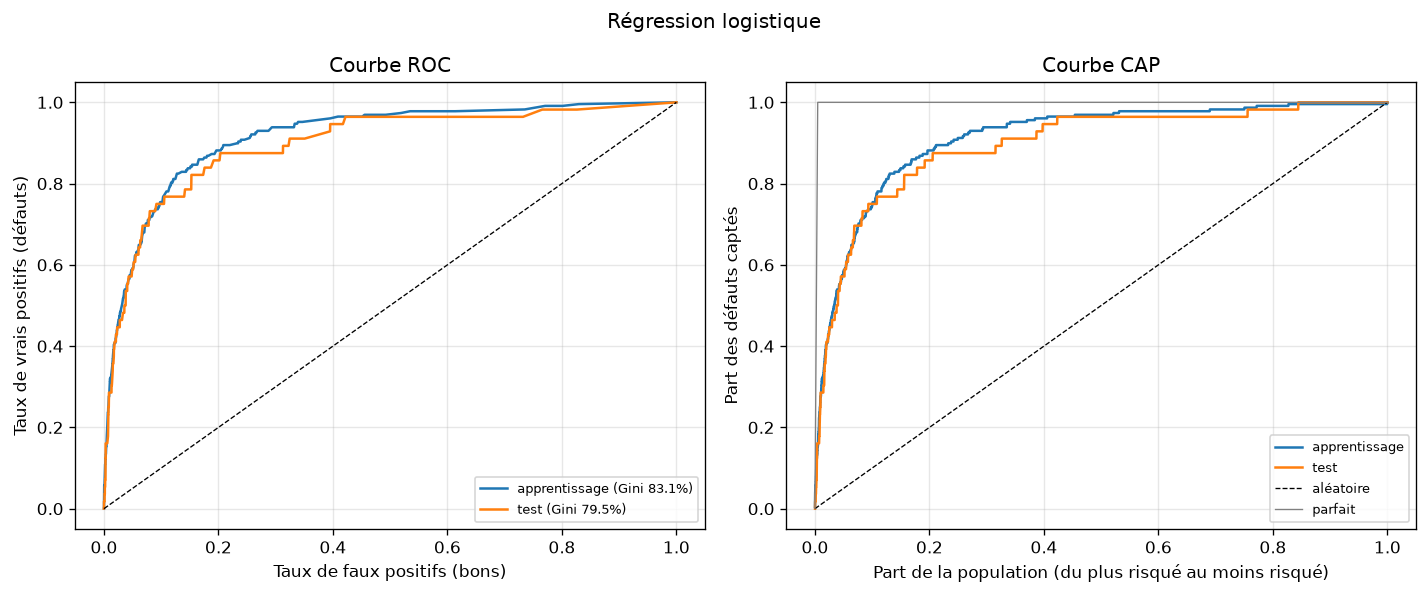

In [13]:
fig = plot_roc_cap({"apprentissage": (app_f[TARGET], s_app), "test": (test_f[TARGET], s_test)},
                   titre="Régression logistique")
plt.show()

### Lift par décile (échantillon de test)

In [14]:
table_lift(test_f[TARGET], s_test)

decile,n,n_defaut,taux_defaut,lift,part_defauts_captes,lift_cumule
i64,u32,f64,f64,f64,f64,f64
1,1180,42.0,0.035593,7.49428,0.75,7.49428
2,1179,6.0,0.005089,1.071519,0.857143,4.284261
3,1179,1.0,0.000848,0.178587,0.875,2.91609
4,1179,4.0,0.003393,0.714346,0.946429,2.36577
5,1179,1.0,0.000848,0.178587,0.964286,1.928408
6,1179,0.0,0.0,0.0,0.964286,1.607052
7,1179,0.0,0.0,0.0,0.964286,1.377501
8,1179,1.0,0.000848,0.178587,0.982143,1.227653
9,1179,1.0,0.000848,0.178587,1.0,1.111101


## 5.2 Modèle concurrent : gradient boosting

Le cours (5.2) impose un modèle concurrent, **jamais retenu comme modèle final** en scoring réglementaire
(interprétabilité, gouvernance, risque de surapprentissage avec peu de défauts). Il sert de **référence de performance** :
mesurer ce que la contrainte d'une grille lisible coûte en Gini.

Il est estimé sur les **variables brutes préparées** (sortie de `2`, candidates de `3`), sans discrétisation : c'est le
concurrent le plus exigeant. Régularisation adaptée à un faible nombre de défauts : arbres de profondeur 3, feuilles
d'au moins 200 dossiers, arrêt précoce sur une validation interne (AUC).

In [15]:
brut = pl.read_parquet(BASE_PREP)
VARS_GB = [v for v in json.loads(CANDIDATES.read_text(encoding="utf-8")) if v in brut.columns]
brut_app  = brut.filter(pl.col("echantillon") == "apprentissage")
brut_test = brut.filter(pl.col("echantillon") == "test")

gb = gradient_boosting(brut_app, VARS_GB, TARGET)
p_gb_app, p_gb_test = predire_gb(gb, brut_app), predire_gb(gb, brut_test)
print(f"{len(VARS_GB)} variables brutes | {gb.n_iter_} itérations retenues par arrêt précoce")

perf = pl.concat([perf_lr, pl.DataFrame([performance(brut_app[TARGET], p_gb_app, "gradient boosting — apprentissage"),
                                         performance(brut_test[TARGET], p_gb_test, "gradient boosting — test")])])
perf

51 variables brutes | 106 itérations retenues par arrêt précoce


modele,n,n_defaut,auc,gini,gini_ic_bas,gini_ic_haut,ks
str,i64,i64,f64,f64,f64,f64,f64
"""logistique — apprentissage""",47156,228,0.915498,0.830996,0.781056,0.880935,0.697303
"""logistique — test""",11791,56,0.897442,0.794884,0.685534,0.904234,0.671677
"""gradient boosting — apprentissage""",47156,228,0.956636,0.913271,0.876291,0.950251,0.781968
"""gradient boosting — test""",11791,56,0.912985,0.825969,0.723925,0.928014,0.713385


### Comparaison sur le test : test de DeLong (cours 5.3.1.4)

Les deux modèles sont évalués sur les mêmes dossiers : le test de DeLong dit si l'écart d'AUC dépasse la seule
variabilité d'échantillonnage.

Gini logistique = 79.5% | Gini gradient boosting = 82.6% | écart = -3.1% | p-value DeLong = 0.192


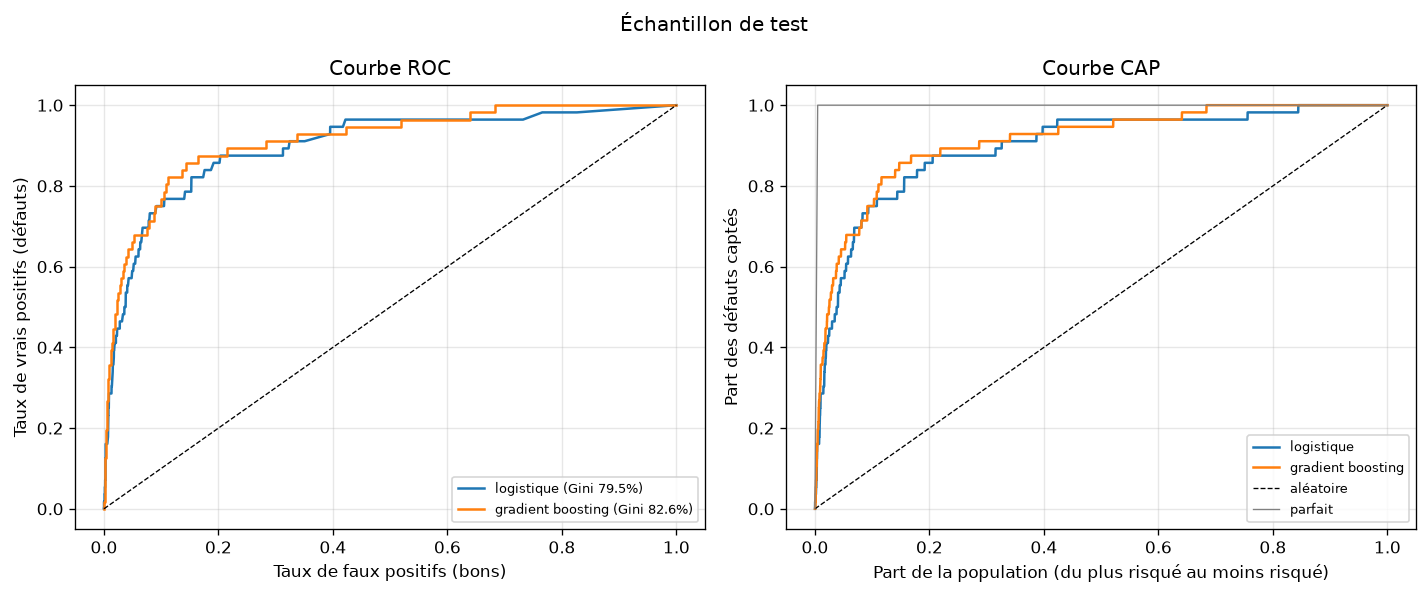

In [16]:
# Les deux bases sont dans le même ordre de lignes (même base de départ, même filtre)
assert (brut_test[TARGET] == test_f[TARGET]).all()
delong = test_delong(test_f[TARGET].to_numpy(), s_test, p_gb_test)
print(f"Gini logistique = {2*delong['auc_a']-1:.1%} | Gini gradient boosting = {2*delong['auc_b']-1:.1%} | "
      f"écart = {delong['ecart_gini']:+.1%} | p-value DeLong = {delong['pvalue']:.3f}")

fig = plot_roc_cap({"logistique": (test_f[TARGET], s_test), "gradient boosting": (brut_test[TARGET], p_gb_test)},
                   titre="Échantillon de test")
plt.show()

### 5.2 bis Diagnostic : le boosting montre-t-il comment améliorer la logistique ?

Le modèle concurrent sert de **référence de performance** : s'il fait nettement mieux, l'écart indique ce que la
logistique laisse de côté. Trois sources d'écart sont possibles : des **variables** absentes du modèle, une **forme**
de la relation plus fine que nos classes, ou des **interactions** entre variables. Pour les séparer, plusieurs
variantes sont comparées.

Avec 56 défauts, le Gini de test a un IC95 % de ±11 points : un écart de 3 points n'y est pas significatif (DeLong
ci-dessus). Chaque variante est donc aussi évaluée en **validation croisée à 5 plis sur l'apprentissage** (228
défauts, chaque dossier noté par un modèle estimé sans lui), mesure plus stable. Le test reste affiché pour
information.

| Variante | Isole |
|----------|-------|
| logistique, 39 variables discrétisées sans sélection | apport des variables écartées au stepwise |
| boosting profondeur 1 (additif, sans interaction) | variables et forme fine, sans interactions |
| boosting sur les 9 variables du modèle, brutes | forme fine des variables retenues (+ interactions) |
| boosting sur les 9 variables du modèle, en classes | interactions seules |

In [17]:
VARS_MODELE_BRUT = [v for v in VARS_MODELE if v in brut.columns]
app_cat = app_f.with_columns(pl.col(VARS_MODELE).cast(pl.String))
test_cat = test_f.with_columns(pl.col(VARS_MODELE).cast(pl.String))
VARIANTES_GB = [   # (nom, base apprentissage, base test, variables, paramètres)
    ("boosting, 51 var. brutes (concurrent)", brut_app, brut_test, VARS_GB, {}),
    ("boosting, 51 var. brutes, profondeur 1", brut_app, brut_test, VARS_GB, dict(max_depth=1, learning_rate=0.1)),
    ("boosting, 9 var. du modèle, brutes", brut_app, brut_test, VARS_MODELE_BRUT, {}),
    ("boosting, 9 var. du modèle, brutes, profondeur 1", brut_app, brut_test, VARS_MODELE_BRUT,
     dict(max_depth=1, learning_rate=0.1)),
    ("boosting, 9 var. du modèle, en classes", app_cat, test_cat, VARS_MODELE, {}),
]
gini = lambda y, s: 2 * roc_auc_score(y, s) - 1
diag = []
for nom, vars_ in (("logistique retenue (9 var.)", VARS_MODELE), ("logistique, 39 var. sans sélection", VARS)):
    m = ajuster_logit(app_f, vars_, TARGET)
    diag.append({"modele": nom, "gini_app": gini(app_f[TARGET], m.score_lineaire(app_f)),
                 "gini_cv5": gini_cv_logit(app_f, vars_, TARGET), "gini_test": gini(test_f[TARGET], m.score_lineaire(test_f))})
for nom, da, dt, vars_, params in VARIANTES_GB:
    g_ = gradient_boosting(da, vars_, TARGET, **params)
    diag.append({"modele": nom, "gini_app": gini(da[TARGET], predire_gb(g_, da)),
                 "gini_cv5": gini_cv_gb(da, vars_, TARGET, **params), "gini_test": gini(dt[TARGET], predire_gb(g_, dt))})
diag = pl.DataFrame(diag).with_columns(ecart_app_cv=pl.col("gini_app") - pl.col("gini_cv5"))
diag

modele,gini_app,gini_cv5,gini_test,ecart_app_cv
str,f64,f64,f64,f64
"""logistique retenue (9 var.)""",0.830996,0.820268,0.794884,0.010728
"""logistique, 39 var. sans sélection""",0.840309,0.802483,0.798837,0.037827
"""boosting, 51 var. brutes (concurrent)""",0.913271,0.799302,0.825969,0.113969
"""boosting, 51 var. brutes, profondeur 1""",0.846772,0.814497,0.815275,0.032275
"""boosting, 9 var. du modèle, brutes""",0.8812,0.800102,0.789607,0.081099
"""boosting, 9 var. du modèle, brutes, profondeur 1""",0.842755,0.812936,0.802724,0.02982
"""boosting, 9 var. du modèle, en classes""",0.856786,0.808879,0.791685,0.047907


#### Variables importantes pour le boosting

Importance par permutation (perte d'AUC quand la variable est mélangée), sur l'apprentissage. Une variable importante
pour le boosting mais absente du modèle est une piste.

In [18]:
imp_gb = importance_permutation_gb(gb, brut_app, TARGET).with_columns(
    dans_le_modele=pl.col("variable").is_in(VARS_MODELE), discretisee_ch4=pl.col("variable").is_in(VARS))
imp_gb.head(15)

variable,importance_auc,ecart_type,dans_le_modele,discretisee_ch4
str,f64,f64,bool,bool
"""MINSOLDE_PAR""",0.016806,0.001741,true,true
"""horsbilan""",0.015592,0.001661,true,true
"""RATIO_SOLDE_MOYEN_SUR_EPARGNE""",0.006149,0.0005,false,true
"""ENCOURS_PAR""",0.00552,0.001122,true,true
"""SOLDE_EVOLUTION_T_vs_T1""",0.004681,0.000556,true,true
"""NBJDE_RATIO_A_vs_A1""",0.004244,0.000691,false,true
"""CRTAD_AG_NBJDE_BA""",0.003836,0.00063,true,true
"""CRTAV_IND_0165""",0.003678,0.001351,false,false
"""NBECR_EVOLUTION_A_vs_A1""",0.002628,0.000638,false,true


#### Ajout, une à une, des variables écartées

Chaque variable discrétisée absente du modèle est ajoutée seule. On regarde le gain de Gini en validation croisée et la
conformité aux tests du cours 5.1 (modalités significatives, signes, monotonie, VIF) de **toutes** les variables du
modèle augmenté.

In [19]:
ajouts = ajouts_un_a_un(app_f, test_f, VARS_MODELE, [v for v in VARS if v not in VARS_MODELE], TARGET,
                        alpha=ALPHA, seuil_vif=SEUIL_VIF)
ajouts.head(12)

variable,gini_cv,gini_test,conforme,variables_non_conformes,gain_cv
str,f64,f64,bool,str,f64
"""RATIO_NBJDEB_NONAUTO_SUR_NBJDEB""",0.822834,0.799571,false,"""solde_crediteur""",0.002566
"""NBJ_ARR_SS_max_Mm1_Mm3""",0.822239,0.797783,true,"""""",0.001971
"""RATIO_SOLDE_MOYEN_SUR_EPARGNE""",0.821619,0.791402,false,"""RATIO_SOLDE_MOYEN_SUR_EPARGNE""",0.001351
"""SOLDE_RATIO_T_vs_HIST""",0.821576,0.795433,false,"""solde_crediteur, SOLDE_RATIO_T_vs_HIST""",0.001308
"""SOLDE_PENTE_5T""",0.821502,0.793206,false,"""solde_crediteur, SOLDE_PENTE_5T""",0.001234
"""ANCIENNETE_modif""",0.821443,0.809979,false,"""solde_crediteur, anciennete_jour_sain_M0, ANCIENNETE_modif""",0.001175
"""CRTAD_IND_0015""",0.821178,0.798942,false,"""solde_crediteur, CRTAD_IND_0015""",0.00091
"""NBJ_ARR_SS_max_Mm7_Mm9""",0.820962,0.794931,true,"""""",0.000694
"""CRTAD_AG_MVTAFF_IND_0010""",0.820872,0.795,false,"""solde_crediteur, CRTAD_AG_MVTAFF_IND_0010""",0.000604


**Lecture** : **le boosting n'indique pas de piste d'amélioration robuste de la logistique.**

| Modèle | Gini apprentissage | Gini CV 5 plis | Gini test |
|--------|--------------------|----------------|-----------|
| **logistique retenue (9 var.)** | 83,1 % | **82,0 %** | 79,5 % |
| logistique, 39 var. sans sélection | 84,0 % | 80,2 % | 79,9 % |
| boosting, 51 var. brutes (concurrent) | 91,3 % | 79,9 % | 82,6 % |
| boosting, 51 var. brutes, profondeur 1 | 84,7 % | 81,4 % | 81,5 % |
| boosting, 9 var. du modèle, brutes | 88,1 % | 80,0 % | 79,0 % |
| boosting, 9 var. du modèle, brutes, profondeur 1 | 84,3 % | 81,3 % | 80,3 % |
| boosting, 9 var. du modèle, en classes | 85,7 % | 80,9 % | 79,2 % |

- **L'avance du concurrent sur le test (+3,1 points) ne se reproduit pas en validation croisée.** En CV, c'est la
  logistique retenue qui a le meilleur Gini (82,0 % contre 79,9 %). Le boosting surapprend : 11 points d'écart entre
  apprentissage et CV, contre 1 point pour la logistique. Son avance sur le test relève de la variabilité des 56 défauts
  (DeLong p = 0,19).
- **Interactions** : le boosting additif (profondeur 1) fait mieux en CV que celui de profondeur 3, et le boosting
  sur les 9 variables en classes, qui ne peut apporter que des interactions, reste sous la logistique. Rien ne justifie
  d'ajouter des croisements de variables.
- **Forme des relations** : le boosting sur les 9 variables brutes, qui voit leur forme exacte, ne dépasse pas la
  logistique sur leurs classes (81,3 % au mieux en CV). La discrétisation du ch. 4 ne coûte pas de Gini.
- **Variables** : sans sélection, les 39 variables perdent 1,8 point en CV. Parmi les variables importantes pour le
  boosting mais absentes du modèle (`RATIO_SOLDE_MOYEN_SUR_EPARGNE`, `NBJDE_RATIO_A_vs_A1`, `NBECR_EVOLUTION_A_vs_A1`),
  aucune n'apporte de gain une fois ajoutée : leur information est déjà portée par les variables retenues. Le meilleur
  ajout conforme, `NBJ_ARR_SS_max_Mm1_Mm3`, gagne 0,2 point en CV, sous le seuil de 0,5 point du stepwise.

**Décision** : le modèle à 9 variables est conservé tel quel. La contrainte de lisibilité d'une grille ne coûte pas de
Gini mesurable sur ce segment.

## Export

In [20]:
SORTIE_MOD.parent.mkdir(parents=True, exist_ok=True)
SORTIE_MOD.write_text(json.dumps({
    "variables": VARS_MODELE,
    "fusions": {v: {str(a): b for a, b in m.items()} for v, m in FUSIONS.items()},
    "beta0": modele.beta0,
    "coefficients": test_modalites.select("variable", "classe", "beta").to_dicts(),
}, ensure_ascii=False, indent=1), encoding="utf-8")

exporter_excel({"journal_stepwise": res.journal, "coefficients": test_modalites, "tests_variables": test_variables,
                "performance": perf, "iv_final": iv_final, "lasso": lasso,
                "diagnostic_concurrent": diag, "importance_gb": imp_gb, "ajouts_un_a_un": ajouts}, SORTIE_XLS)
print(f"Modèle : {SORTIE_MOD}\nTables : {SORTIE_XLS}")

Modèle : C:\Users\anisz\OneDrive\Desktop\Scorign\outputs\modele\modele_joint_v2.json
Tables : C:\Users\anisz\OneDrive\Desktop\Scorign\outputs\modele\modele_joint_v2.xlsx


## Synthèse des décisions

| § | Constat | Décision |
|---|---------|----------|
| 5.1 Préclassement | 40 variables discrétisées, IV final de 0,02 à 1,9 | ordre d'examen par IV décroissant |
| 5.4 LASSO | 39 variables sur 40 gardent un coefficient non nul (C = 13,9) | peu sélectif : non retenu comme méthode, simple contrôle |
| 5.5 Stepwise | **8 variables retenues** ; 32 écartées : 18 réduites à une classe après fusions, 12 rendent une variable déjà retenue non conforme (redondance), 2 gain de Gini < 0,5 point | modèle retenu |
| 5.1 Tests | LR global = 633 (14 ddl, p < 10⁻¹²⁵) ; toutes les variables significatives (LR p ≤ 0,044), toutes les modalités significatives, IC95 % des OR > 1, β monotones, VIF ≤ 5 | **modèle conforme à tous les tests** |
| 5.1 Fusions | `SOLDE_RATIO_T_vs_HIST` 3 → 2 classes, `ANCIENNETE_modif` 3 → 2 classes | retour au ch. 4 (fusion de la classe non significative avec sa voisine) |
| 5.3 Performance | Gini **82,4 %** en apprentissage, **74,8 %** en test (IC95 % 65 – 85 %), KS 62 % en test ; 64 % des défauts du test dans le premier décile (lift 6,4) | performance « forte » selon les repères de place (> 60 %) |
| 5.2 Concurrent | gradient boosting : Gini 94,1 % en apprentissage, 79,2 % en test ; écart de +4,4 points non significatif (DeLong, p = 0,07) | la logistique est retenue : la grille coûte peu en Gini, et le boosting surapprend davantage (−15 points entre apprentissage et test, contre −8) |

**Variables du modèle** (par ordre d'entrée) : `MINSOLDE_PAR`, `CRTAD_AG_NBJDE_BA`, `ENCOURS_PAR`, `CAUSE_SAIN_M0`,
`SOLDE_RATIO_T_vs_HIST`, `ANCIENNETE_modif`, `NBECR_EVOLUTION_A_vs_A1`, `NBJ_ARR_SS_max_Mm1_Mm3`. Elles couvrent les familles
dégagées en 3 : trésorerie (solde minimum, jours débiteurs), patrimoine (encours), historique de défaut, tendance (solde,
écritures), ancienneté et arriérés récents.

**Points de vigilance** :

- **Écart apprentissage / test de 8 points** : attendu avec 200 défauts en apprentissage (l'IC95 % du Gini de test fait
  ±10 points) ; l'échantillon OOT tranchera.
- **Classes de β très proches** : `MINSOLDE_PAR` 2 / 3 (β 0,95 et 0,98), `CRTAD_AG_NBJDE_BA` 4 / 5 (1,70 et 1,77),
  `NBECR_EVOLUTION_A_vs_A1` 2 / 3 (0,55 et 0,63). La monotonie est respectée mais l'écart est faible : **à toi de décider**
  s'il faut les fusionner (parcimonie) — gain de lisibilité, perte de Gini a priori négligeable.
- Les paramètres de discrétisation ont été comparés sur le test (cf. 4) : la validation indépendante sera l'OOT.

> **Prochaine étape** : grille de score (ch. 6, notebook `6`).